 PRACTICAL 6: RNN/LSTM/GRU POETRY & LYRICS GENERATION


TensorFlow version: 2.20.0
Number of characters: 198560
Vocabulary size: 28
Characters: ['\n', ' ', "'", 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'y', 'z']
Number of training sequences: 66154
X shape: (66154, 100)
y shape: (66154,)
Training sequences: 59538
Validation sequences: 6616


TRAINING SIMPLE RNN


Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 64)        │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_7 (SimpleRNN)        │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 28)             │         3,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,108 (117.61 KB)

 Trainable params: 30,108 (117.61 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 79,900 (312.11 KB)

 Trainable params: 79,900 (312.11 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
466/466 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.3507 - loss: 2.1951 - val_accuracy: 0.4637 - val_loss: 1.7628
Epoch 2/30
466/466 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.5147 - loss: 1.5943 - val_accuracy: 0.5839 - val_loss: 1.3769
Epoch 3/30
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.6070 - loss: 1.2907 - val_accuracy: 0.6646 - val_loss: 1.1082
Epoch 4/30
466/466 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6714 - loss: 1.0755 - val_accuracy: 0.7269 - val_loss: 0.9136
Epoch 5/30
466/466 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7184 - loss: 0.9184 - val_accuracy: 0.7668 - val_loss: 0.7657
Epoch 6/30
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.7561 - loss: 0.7904 - val_accuracy: 0.8111 - val_loss: 0.6439
Epoch 7/30
466/466 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.7906 - loss: 0.6798 - val_accuracy: 0.8401 - val_loss: 0.5382
Epoch 8/30
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8191 - loss: 0.5878 - val_accur

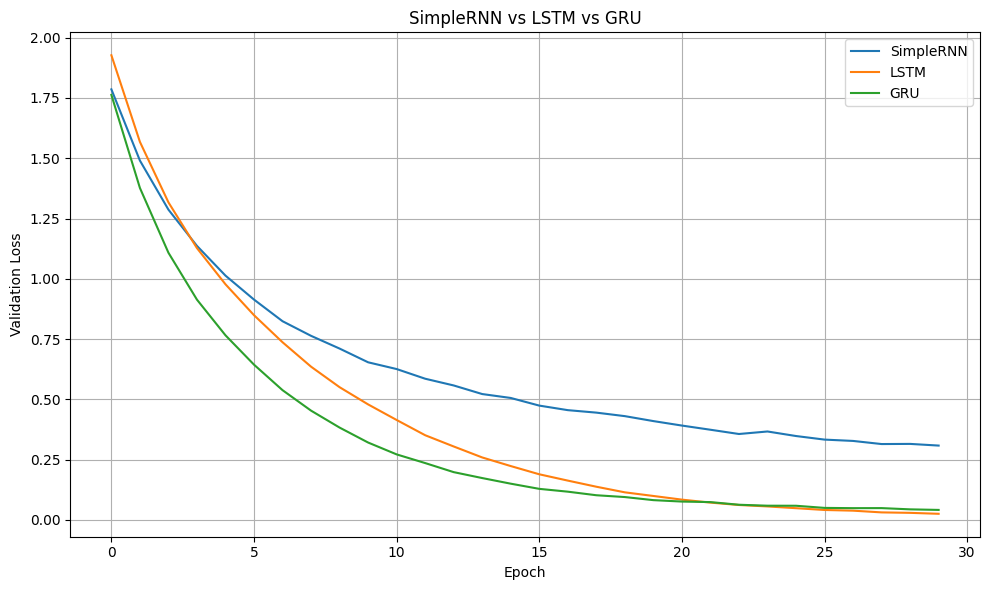



PRACTICAL 6 COMPLETED

Objective:
Train a character-level recurrent neural network
on poetry and generate new text.

Models compared:
1. SimpleRNN
2. LSTM
3. GRU

Architecture:
Character Index
      ↓
Embedding
      ↓
Recurrent Layer
      ↓
Dense + Softmax
      ↓
Next Character

Sequence Length: 100
Temperature: 0.45
Early Stopping: Enabled
Maximum Epochs: 30



In [43]:
# ============================================================
# PRACTICAL 6
# RNN / LSTM / GRU POETRY / LYRICS GENERATION
# CHARACTER-LEVEL TEXT GENERATION
# ============================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)


# ============================================================
# STEP 1: POETRY CORPUS
# ============================================================
#
# IMPORTANT:
# This is CHARACTER-LEVEL generation.
#
# For a real project, replace corpus_text with a large
# poetry/lyrics .txt file containing 100,000+ characters.
#
# The corpus below is intentionally repeated to make this
# demonstration sufficiently large for Colab.
# ============================================================

base_poem = """
the moon is shining softly over the quiet sea
and silver stars are waking in the evening sky
the gentle wind is moving through the trees
while waves are rising softly by the shore

the night is calm and peaceful everywhere
the world is sleeping underneath the light
a distant bird is singing in the air
and dreams are slowly growing through the night

when morning comes the golden sun appears
and paints the clouds with colors bright and warm
the flowers open after quiet hours
and birds begin their songs to greet the dawn

the fields are green beneath the morning sun
the river moves like silver through the land
the birds are singing and the day has come
while flowers dance beside the river bank

i walk alone beneath the morning sky
and watch the clouds move slowly far away
the wind is whispering softly as it passes
and birds are singing at the break of day

i hear a song within the falling rain
a quiet melody upon the roof
the drops are dancing down the window pane
and every cloud becomes a silver proof

the rain will come and rain will disappear
the clouds will pass and skies will turn to blue
and when the darkness brings a hidden fear
remember there is always light for you

love is a light that lives within the heart
a gentle flame that never fades away
although the world may sometimes make us part
true love can find another path each day

love is a river flowing to the sea
it moves through every valley and every land
it carries dreams and sets the spirit free
and leaves a gentle memory in the sand

love can be found in simple words and smiles
in quiet moments shared beneath the trees
it can remain through many distant miles
and travel softly on the evening breeze

the heart can break but it can heal again
the darkest night will slowly turn to dawn
and after every storm and every rain
a brighter day will surely still move on

do not be afraid when darkness fills the sky
for stars are always waiting in the night
and even when the clouds are passing by
the morning will return with golden light

the road is long and sometimes hard to walk
the hills are high and distant seems the goal
but every step and every quiet thought
can make a stronger and more hopeful soul

i walk beside the river in the spring
and watch the water shining in the sun
i hear the distant morning robins sing
and know another day has just begun

the river flows beneath the ancient trees
and carries fallen leaves along its way
the branches move gently with the breeze
while sunlight dances on the stream all day

the autumn leaves are falling to the ground
and golden colors fill the quiet lane
the wind is carrying every gentle sound
and clouds are gathering before the rain

the winter moon is shining cold and bright
the snow is resting softly on the hill
the village disappears into the night
and everything around becomes so still

then spring returns with flowers everywhere
the fields are green the sky is clear and wide
the birds are building nests beneath the air
and little streams are running by our side

the summer morning opens like a flower
the sunlight fills the garden with its glow
the golden hours seem to last forever
while warm and gentle winds begin to blow

a little bird is sitting on a tree
and singing softly to the morning light
its song is like a message meant for me
a promise that the world will soon be bright

the garden holds a thousand shades of green
the roses open underneath the sun
the brightest flowers that i have ever seen
are shining when the morning has begun

a rose may bloom and later fade away
a flower may be forgotten with the years
but memories can live beyond a day
and love can turn our sadness into tears

the stars may fade when morning comes at last
the moon may disappear into the blue
but every beautiful and precious past
will leave a little light behind for you

i dream of walking through a distant land
where mountains touch the clouds above the sea
where flowers grow like jewels upon the sand
and every river carries dreams to me

i dream of castles shining in the sun
with gardens filled with roses red and white
where every child can laugh and freely run
and every heart is filled with love and light

beyond the hills another road begins
beyond the road another dream may grow
and even when the journey sometimes turns
we find a place where peaceful waters flow

the ocean calls from far across the land
its waves are rising gently with the tide
the wind is carrying stories from the sand
and distant ships are moving side by side

the ocean sings a song that has no end
a song of waves and wind and distant rain
it calls the lonely traveler as a friend
and brings the wandering heart to life again

the mountains stand beneath the open sky
their snowy peaks are shining in the sun
the clouds are slowly moving high above
and every valley waits for day begun

the forest whispers secrets in the breeze
the branches move like dancers in the light
the sunlight falls between the ancient trees
and turns the quiet forest warm and bright

a thousand leaves are moving in the air
a thousand birds are singing from the trees
the world is full of beauty everywhere
when morning sunlight travels with the breeze

the evening comes with shadows soft and deep
the golden sunlight fades beyond the hill
the birds return and slowly go to sleep
and all the world around becomes so still

the moon appears above the quiet town
and silver light is shining on the street
the tired world is slowly settling down
and night is making everything complete

a candle shines beside an open door
a gentle light is glowing in the room
the quiet house is asking nothing more
while moonlight enters through the window

i remember days that passed so long ago
the faces and the voices of my friends
the places where the summer flowers grow
the memories that never truly end

some dreams are lost and some dreams remain
some disappear like shadows in the night
but hope can rise like flowers after rain
and turn a little darkness into light

the future waits beyond the distant hill
the road is open and the sky is clear
although the world may sometimes seem so still
there is a brighter morning drawing near

so walk beneath the open morning sky
and let the gentle wind move through your hair
let every little sorrow pass you by
and find a little happiness somewhere

when you are tired and cannot see the way
remember that the stars are shining still
the night will slowly disappear to day
and morning light will rise beyond the hill

there is a song within the human heart
a song of hope a song of love and peace
although the world may sometimes tear apart
the song can bring a moment of release

let every heart remember how to dream
let every soul remember how to care
let every person follow hope's bright beam
and leave a little kindness everywhere

a friend can be a light within the night
a hand to hold when roads are hard to cross
a voice that tells us everything is right
and helps us find our way when we are lost

the simple things are often most important
a smile a word a flower in the spring
a quiet walk a little song of morning
the happiness that ordinary moments bring

the world is full of little things to see
a butterfly a flower and a tree
a child who laughs beside a flowing stream
and all the simple beauty of a dream

the morning birds are singing in the trees
the river sparkles underneath the sun
the flowers dance together with the breeze
and all the world remembers spring has come

the evening stars are shining far above
the moon is looking down upon the sea
the world is filled with quietness and love
and dreams are floating gently back to me

when winter comes and covers all the ground
the trees are sleeping underneath the snow
the world becomes a quiet peaceful sound
and waits for spring to wake and start to grow

when spring arrives the sleeping flowers wake
the green leaves open underneath the sun
the rivers move and little branches shake
and birds return to sing when day has come

when summer comes the fields are full of gold
the warm wind moves across the open plain
the stories of the summer days are told
while clouds appear and disappear like rain

when autumn comes the leaves begin to fall
the golden forest changes every day
the evening wind begins to softly call
and carries summer slowly far away

every season has a song to sing
the winter moon the summer golden sun
the autumn leaves the flowers of the spring
each tells the story of the year begun

life is a journey filled with many roads
some roads are bright and some are dark at night
we carry all our memories and hopes
and search for places filled with warmth and light

we cannot know what waits beyond the door
we cannot see tomorrow's distant face
but every day can offer something more
a chance to find a new and better place

the world may change the years may quickly fly
the rivers may continue to the sea
but dreams can still remain beneath the sky
and hope can still become what we can be

i will remember every gentle song
i will remember every morning light
i will remember places all along
that made the darkest days a little bright

and when the road becomes too hard to walk
i will remember why i started there
i will remember every hopeful thought
and find the strength to continue everywhere

the stars above are shining like a dream
the moon is resting quietly tonight
the river moves beneath a silver beam
and everything is peaceful in the light

the night is not the ending of the day
it is a place where quiet dreams can grow
the darkness does not always mean delay
for morning waits beyond the falling snow

so keep your dreams and let your spirit rise
keep hope alive when everything seems wrong
for somewhere underneath the changing skies
there is a place where you will still belong

the road ahead is waiting just for you
the morning sun is shining on the way
the sky is bright the distant hills are blue
and hope is waiting for another day
"""


# ------------------------------------------------------------
# Make the corpus larger
# ------------------------------------------------------------

corpus_text = (base_poem + "\n") * 20

corpus_text = corpus_text.lower()

print("Number of characters:", len(corpus_text))


# ============================================================
# STEP 2: CHARACTER VOCABULARY
# ============================================================

chars = sorted(set(corpus_text))

char_to_idx = {
    char: i
    for i, char in enumerate(chars)
}

idx_to_char = {
    i: char
    for i, char in enumerate(chars)
}

vocab_size = len(chars)

print("Vocabulary size:", vocab_size)
print("Characters:", chars)


# ============================================================
# STEP 3: CREATE CHARACTER SEQUENCES
# ============================================================

SEQ_LENGTH = 100
STEP = 3

sequences = []
next_chars = []

for i in range(
    0,
    len(corpus_text) - SEQ_LENGTH,
    STEP
):

    sequences.append(
        corpus_text[
            i:i + SEQ_LENGTH
        ]
    )

    next_chars.append(
        corpus_text[
            i + SEQ_LENGTH
        ]
    )

print(
    "Number of training sequences:",
    len(sequences)
)


# ============================================================
# STEP 4: INTEGER ENCODING
# ============================================================

X = np.zeros(
    (
        len(sequences),
        SEQ_LENGTH
    ),
    dtype=np.int32
)

y = np.zeros(
    len(sequences),
    dtype=np.int32
)

for i, seq in enumerate(sequences):

    for t, char in enumerate(seq):

        X[
            i,
            t
        ] = char_to_idx[char]

    y[i] = char_to_idx[
        next_chars[i]
    ]


print("X shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# STEP 5: TRAIN / VALIDATION SPLIT
# ============================================================

split_index = int(
    len(X) * 0.90
)

X_train = X[:split_index]
y_train = y[:split_index]

X_val = X[split_index:]
y_val = y[split_index:]

print(
    "Training sequences:",
    len(X_train)
)

print(
    "Validation sequences:",
    len(X_val)
)


# ============================================================
# STEP 6: BUILD CHARACTER-LEVEL MODEL
# ============================================================

EMBEDDING_DIM = 64
RNN_UNITS = 128


def build_model(cell_type):

    model = Sequential()

    model.add(
        Input(
            shape=(SEQ_LENGTH,)
        )
    )

    model.add(
        Embedding(
            input_dim=vocab_size,
            output_dim=EMBEDDING_DIM
        )
    )

    if cell_type == "SimpleRNN":

        model.add(
            SimpleRNN(
                RNN_UNITS,
                dropout=0.2
            )
        )

    elif cell_type == "LSTM":

        model.add(
            LSTM(
                RNN_UNITS,
                dropout=0.2
            )
        )

    elif cell_type == "GRU":

        model.add(
            GRU(
                RNN_UNITS,
                dropout=0.2
            )
        )

    model.add(
        Dense(
            vocab_size,
            activation="softmax"
        )
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ============================================================
# STEP 7: EARLY STOPPING
# ============================================================

def get_early_stopping():

    return EarlyStopping(
        monitor="val_loss",
        patience=5,
        min_delta=0.001,
        restore_best_weights=True,
        verbose=1
    )


# ============================================================
# STEP 8: TEMPERATURE SAMPLING
# ============================================================

def sample(predictions, temperature=0.45):

    predictions = np.asarray(
        predictions
    ).astype("float64")

    predictions = np.maximum(
        predictions,
        1e-8
    )

    predictions = np.log(
        predictions
    ) / temperature

    exp_predictions = np.exp(
        predictions -
        np.max(predictions)
    )

    probabilities = (
        exp_predictions /
        np.sum(exp_predictions)
    )

    return np.random.choice(
        len(probabilities),
        p=probabilities
    )


# ============================================================
# STEP 9: TEXT GENERATION
# ============================================================

def generate_text(
    model,
    seed_text,
    length=400,
    temperature=0.45
):

    seed_text = seed_text.lower()

    # Keep only known characters
    seed_text = "".join(
        char
        for char in seed_text
        if char in char_to_idx
    )

    # If seed is longer than sequence length,
    # keep only the last SEQ_LENGTH characters.
    seed_text = seed_text[-SEQ_LENGTH:]

    # Pad short seed
    if len(seed_text) < SEQ_LENGTH:

        seed_text = (
            " " *
            (SEQ_LENGTH - len(seed_text))
            + seed_text
        )

    generated = seed_text

    for _ in range(length):

        encoded = np.array(
            [
                [
                    char_to_idx[c]
                    for c in generated[-SEQ_LENGTH:]
                ]
            ],
            dtype=np.int32
        )

        predictions = model.predict(
            encoded,
            verbose=0
        )[0]

        next_index = sample(
            predictions,
            temperature
        )

        next_char = idx_to_char[
            next_index
        ]

        generated += next_char

    return generated


# ============================================================
# STEP 10: TRAIN SIMPLE RNN
# ============================================================

print("\n")
print("=" * 70)
print("TRAINING SIMPLE RNN")
print("=" * 70)

rnn_model = build_model(
    "SimpleRNN"
)

rnn_model.summary()

history_rnn = rnn_model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=30,
    batch_size=128,
    callbacks=[
        get_early_stopping()
    ],
    verbose=1
)


# ============================================================
# STEP 11: SIMPLE RNN OUTPUT
# ============================================================

rnn_output = generate_text(
    rnn_model,
    "love is a",
    length=500,
    temperature=0.45
)

print("\n")
print("=" * 70)
print("SIMPLE RNN GENERATED TEXT")
print("=" * 70)

print(rnn_output)


# ============================================================
# STEP 12: TRAIN LSTM
# ============================================================

print("\n")
print("=" * 70)
print("TRAINING LSTM")
print("=" * 70)

lstm_model = build_model(
    "LSTM"
)

lstm_model.summary()

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=30,
    batch_size=128,
    callbacks=[
        get_early_stopping()
    ],
    verbose=1
)


# ============================================================
# STEP 13: LSTM OUTPUT
# ============================================================

lstm_output = generate_text(
    lstm_model,
    "love is a",
    length=500,
    temperature=0.45
)

print("\n")
print("=" * 70)
print("LSTM GENERATED TEXT")
print("=" * 70)

print(lstm_output)


# ============================================================
# STEP 14: TRAIN GRU
# ============================================================

print("\n")
print("=" * 70)
print("TRAINING GRU")
print("=" * 70)

gru_model = build_model(
    "GRU"
)

gru_model.summary()

history_gru = gru_model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=30,
    batch_size=128,
    callbacks=[
        get_early_stopping()
    ],
    verbose=1
)


# ============================================================
# STEP 15: GRU OUTPUT
# ============================================================

gru_output = generate_text(
    gru_model,
    "love is a",
    length=500,
    temperature=0.45
)

print("\n")
print("=" * 70)
print("GRU GENERATED TEXT")
print("=" * 70)

print(gru_output)


# ============================================================
# STEP 16: LOSS COMPARISON
# ============================================================

print("\n")
print("=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

rnn_best = min(
    history_rnn.history["val_loss"]
)

lstm_best = min(
    history_lstm.history["val_loss"]
)

gru_best = min(
    history_gru.history["val_loss"]
)

print(
    f"SimpleRNN | Best Validation Loss: {rnn_best:.4f}"
)

print(
    f"LSTM      | Best Validation Loss: {lstm_best:.4f}"
)

print(
    f"GRU       | Best Validation Loss: {gru_best:.4f}"
)


# ============================================================
# STEP 17: GENERATED TEXT COMPARISON
# ============================================================

print("\n")
print("=" * 70)
print("GENERATED TEXT COMPARISON")
print("=" * 70)

print("\n--- SIMPLE RNN ---\n")
print(rnn_output)

print("\n--- LSTM ---\n")
print(lstm_output)

print("\n--- GRU ---\n")
print(gru_output)


# ============================================================
# STEP 18: LOSS CURVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history_rnn.history["val_loss"],
    label="SimpleRNN"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="LSTM"
)

plt.plot(
    history_gru.history["val_loss"],
    label="GRU"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.title(
    "SimpleRNN vs LSTM vs GRU"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# STEP 19: FINAL INFORMATION
# ============================================================

print("\n")
print("=" * 70)
print("PRACTICAL 6 COMPLETED")
print("=" * 70)

print("""
Objective:
Train a character-level recurrent neural network
on poetry and generate new text.

Models compared:
1. SimpleRNN
2. LSTM
3. GRU

Architecture:
Character Index
      ↓
Embedding
      ↓
Recurrent Layer
      ↓
Dense + Softmax
      ↓
Next Character

Sequence Length: 100
Temperature: 0.45
Early Stopping: Enabled
Maximum Epochs: 30
""")